# 🤝 02 · Distributional Semantics and Co-occurrence

> **Module 03 – Text to Numbers and Word Embeddings** · Notebook 2 of 9
> Course notes: page 6 (*"I like going __ my old house – can you predict? to, near, inside, around, under, over … Given context, possible words that make a meaningful sentence are very less, because other words dictate"*), page 7 (*"When you give correct order, it is an underlying label"*), page 9 (the distributed / distributional table)

> *"You shall know a word by the company it keeps."* — J. R. Firth, 1957

Notebook 01 ended with an idea: describe a word by **where it appears**. Here we make "where" much more precise: not *which document*, but **which neighbouring words**. That is called **distributional semantics** – a word's meaning is the distribution of words around it.

### 🎯 What you will learn
| # | Idea |
|---|---|
| 1 | Why context *dictates* which words can fill a gap (the notes' missing-word game) |
| 2 | The **word–word co-occurrence matrix** with a context window |
| 3 | **Cosine similarity**, and why raw counts are dominated by words like *the* |
| 4 | **PPMI** – re-weighting counts by how *surprising* they are |
| 5 | Squashing long sparse rows into short dense vectors with the **SVD** |
| 6 | The two ideas the notes separate: **distributed** representation vs **distributional** semantics |

## 0 · Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ---------- one consistent, clean plotting style for the whole notebook ----------
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948",
         ink="#0b0b0b", muted="#52514e", grid="#e6e5e1")
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": C["muted"], "axes.labelcolor": C["ink"], "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "legend.frameon": False,
    "lines.linewidth": 2.0, "font.size": 10.5,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
                       ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
})
np.set_printoptions(precision=4, suppress=True)
from collections import Counter

---
## 1 · The variables 📖

| Symbol | Meaning | Example |
|---|---|---|
| $n$ | vocabulary size | 75 |
| $w_i$ | the $i$-th vocabulary word | `king` |
| $m$ | **window size**: how many words on each side count as "context" | 3 |
| $X_{ij}$ | **co-occurrence count**: how often $w_j$ appears within $m$ words of $w_i$ | 120 |
| $X$ | the $n\times n$ matrix of all counts; row $i$ describes word $w_i$ | – |
| $P(i,j)$ | probability that a random (word, context) pair is $(w_i,w_j)$: $X_{ij}/\sum_{ab}X_{ab}$ | – |
| $P(i)$, $P(j)$ | how often $w_i$ appears as a word / $w_j$ as a context: row and column sums of $P$ | – |
| $PMI(i,j)$ | pointwise mutual information $\log\dfrac{P(i,j)}{P(i)P(j)}$: >0 if they meet *more* often than chance | 1.3 |
| $PPMI(i,j)$ | positive PMI: $\max(0,PMI)$ | – |
| $\cos(a,b)$ | $\dfrac{a\cdot b}{\lVert a\rVert\lVert b\rVert}$ | 0.9 |
| $k$ | number of dimensions kept after the SVD | 10 |

---
## 2 · Context dictates the word 🧩

The notes' game: *"I like going __ my old house"*. Only a handful of words fit – *to, near, inside, around, under, over*. Out of tens of thousands of English words, the context rules out almost all of them.

Two consequences, both from the notes:
* **Meaning is in the context.** Words that fit the same gaps (*to / near / into*) must be related.
* **Free labels.** We never need a human to label anything: any real sentence with one word hidden is a training example, and the hidden word is the label (*"when you give correct order, it is an underlying label"*). This is why word2vec – and GPT – can learn from raw text.

---
## 3 · A corpus with known meanings 📚

To check whether a method *recovers* meaning, we need text where we know the meaning in advance. The generator below writes sentences about:
* **8 people** – each has three hidden attributes: *royal / common*, *male / female*, *adult / young*. A person sentence contains the person and one context word for each of their attributes (e.g. *king → palace, he, works*).
* **things** in 4 topics: fruit, drink, money, river (note: *bank* is a context word for **both** money and river).
* 20 copies of the notes' sentence *"i like going to my old house"*.

No word is ever told its attributes – they are only visible through the company it keeps.

In [2]:
PEOPLE = {   # word: (status, gender, age)
    "king": ("royal", "male", "adult"),     "queen": ("royal", "female", "adult"),
    "prince": ("royal", "male", "young"),   "princess": ("royal", "female", "young"),
    "man": ("common", "male", "adult"),     "woman": ("common", "female", "adult"),
    "boy": ("common", "male", "young"),     "girl": ("common", "female", "young"),
}
POOLS = {    # context words that describe each attribute
    "royal": ["palace", "crown", "throne", "kingdom"],  "common": ["village", "farm", "market", "cottage"],
    "male": ["he", "his", "him", "beard"],              "female": ["she", "her", "hers", "dress"],
    "adult": ["works", "office", "married", "tax"],     "young": ["plays", "school", "toys", "small"],
}
THINGS = {   # topic: (topic words, context words)
    "fruit": (["mango", "apple", "banana", "grape"], ["eat", "sweet", "ripe", "tree", "juicy"]),
    "drink": (["water", "tea", "coffee", "milk"], ["drink", "cup", "hot", "glass", "pour"]),
    "money": (["loan", "money", "interest", "account"], ["bank", "pay", "rupees", "save", "cash"]),
    "river": (["river", "stream", "fish", "boat"], ["bank", "flow", "swim", "shore", "wet"]),
}


def make_corpus(n_sentences=1500, seed=0):
    """Generate a toy corpus whose words have hidden 'meanings' (attributes) we know in advance."""
    rng = np.random.default_rng(seed)
    sentences = []
    for _ in range(n_sentences):
        if rng.random() < 0.55:                                   # a sentence about a person
            word = str(rng.choice(list(PEOPLE)))
            context = [str(rng.choice(POOLS[a])) for a in PEOPLE[word]]   # one word per attribute
            rng.shuffle(context)
            sentences.append(["the", word] + context)
        else:                                                     # a sentence about a thing
            words, ctx = THINGS[rng.choice(list(THINGS))]
            sentences.append(["i", "like", "the", str(rng.choice(words))] + [str(c) for c in rng.choice(ctx, 2, replace=False)])
    sentences += [["i", "like", "going", "to", "my", "old", "house"]] * 20   # the example from the notes
    return sentences

**Generate it and build the vocabulary** (same steps as notebook 01):

In [3]:
sentences = make_corpus()
vocab = sorted({w for s in sentences for w in s})
index = {w: i for i, w in enumerate(vocab)}
n = len(vocab)
print(f"{len(sentences)} sentences, {sum(map(len, sentences))} tokens, n = {n} words")
for s in sentences[:5]:
    print("  ", " ".join(s))

1520 sentences, 8329 tokens, n = 75 words
   i like the money bank pay
   i like the banana tree ripe
   i like the interest cash rupees
   the boy farm toys beard
   the king he married kingdom


---
## 4 · The co-occurrence matrix 🔢

For every position in every sentence, look at the words up to $m$ positions to the left and right, and add 1 to $X_{\text{word},\ \text{context}}$:

$$X_{ij}=\text{number of times } w_j \text{ appears within } m \text{ words of } w_i$$

Row $i$ is then a description of $w_i$: *"how often do you see each other word nearby?"* The matrix is symmetric because "near" works both ways.

In [4]:
def cooccurrence(sentences, index, window=3):
    """X[i, j] = number of times word j appears within `window` positions of word i."""
    X = np.zeros((len(index), len(index)))
    for s in sentences:
        ids = [index[w] for w in s]
        for pos, i in enumerate(ids):
            lo, hi = max(0, pos - window), min(len(ids), pos + window + 1)   # window boundaries
            for ctx_pos in range(lo, hi):
                if ctx_pos != pos:                                          # a word is not its own context
                    X[i, ids[ctx_pos]] += 1
    return X

**Build it with $m=3$** and look at a row:

In [5]:
X = cooccurrence(sentences, index, window=3)
print("X shape:", X.shape, "  symmetric:", np.allclose(X, X.T), "  non-zero entries:", int((X > 0).sum()), "of", n * n)
row = X[index["king"]]
print("most frequent neighbours of 'king':", [(vocab[j], int(row[j])) for j in np.argsort(-row)[:8]])

X shape: (75, 75)   symmetric: True   non-zero entries: 1086 of 5625
most frequent neighbours of 'king': [('the', 95), ('his', 28), ('works', 28), ('beard', 25), ('palace', 25), ('kingdom', 25), ('him', 24), ('throne', 24)]


📊 **Plot:** part of the matrix – the 8 people (rows) against their attribute context words (columns). The hidden attributes are plainly visible: royal people meet *palace/crown/throne/kingdom*, female people meet *she/her/hers/dress*, and so on.

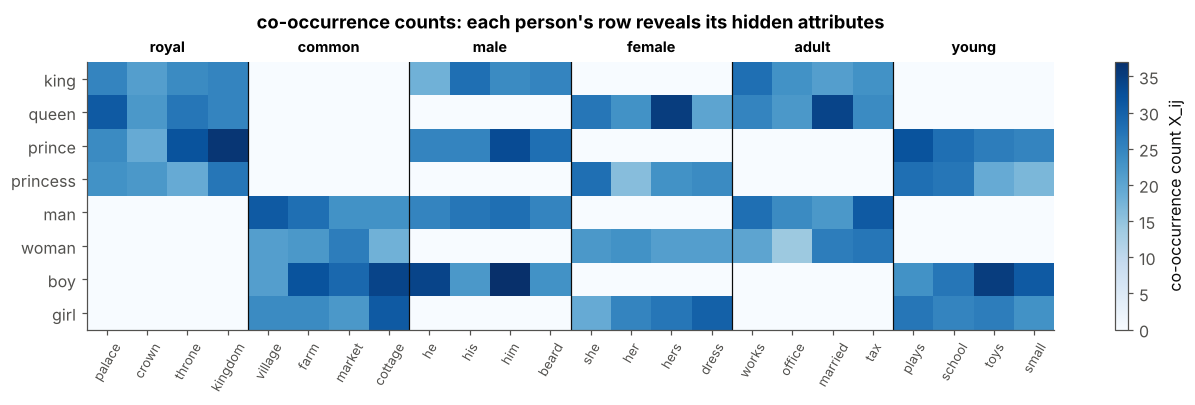

In [6]:
people = list(PEOPLE)
ctx_words = [w for a in ["royal", "common", "male", "female", "adult", "young"] for w in POOLS[a]]
sub = X[np.ix_([index[p] for p in people], [index[c] for c in ctx_words])]
fig, ax = plt.subplots(figsize=(12, 3.8))
im = ax.imshow(sub, cmap="Blues", aspect="auto")
ax.set_yticks(range(len(people)), people); ax.set_xticks(range(len(ctx_words)), ctx_words, rotation=60, fontsize=8.5)
for k in range(1, 6):
    ax.axvline(4 * k - 0.5, color=C["ink"], lw=0.8)
for k, a in enumerate(["royal", "common", "male", "female", "adult", "young"]):
    ax.text(4 * k + 1.5, -0.8, a, ha="center", fontweight="bold", fontsize=9.5)
plt.colorbar(im, ax=ax, label="co-occurrence count X_ij"); ax.grid(False)
ax.set_title("co-occurrence counts: each person's row reveals its hidden attributes", pad=22)
plt.tight_layout(); plt.show()

---
## 5 · Similarity between words 📐

Two words are similar if their rows are similar. We compare rows with **cosine similarity**, which looks at the *direction* of the vectors and ignores their length (a frequent word has big counts, a rare one small counts – that should not matter).

**Step A – normalise every row to length 1.** Then the matrix product $\hat X\hat X^\top$ contains the cosine of every pair of words at once.

In [7]:
def cosine_matrix(M):
    """Cosine similarity between all rows of M."""
    norms = np.linalg.norm(M, axis=1, keepdims=True)
    M_unit = M / np.where(norms == 0, 1, norms)
    return M_unit @ M_unit.T

**Step B – nearest neighbours:** sort a word's row of the cosine matrix and skip the word itself.

In [8]:
def neighbours(S, word, k=5):
    s = S[index[word]].copy()
    s[index[word]] = -np.inf                     # exclude the word itself
    return [(vocab[j], round(float(s[j]), 2)) for j in np.argsort(-s)[:k]]

S_raw = cosine_matrix(X)
for w in ["king", "girl", "mango", "water"]:
    print(f"{w:<6} (raw counts) → {neighbours(S_raw, w)}")

king   (raw counts) → [('man', 0.85), ('prince', 0.85), ('queen', 0.85), ('hers', 0.73), ('his', 0.73)]
girl   (raw counts) → [('boy', 0.85), ('princess', 0.85), ('woman', 0.85), ('him', 0.73), ('dress', 0.73)]
mango  (raw counts) → [('banana', 0.99), ('apple', 0.99), ('grape', 0.98), ('river', 0.79), ('boat', 0.78)]
water  (raw counts) → [('coffee', 0.99), ('milk', 0.99), ('tea', 0.99), ('river', 0.79), ('boat', 0.79)]


**The problem with raw counts.** The groups are already visible, but the similarities are **inflated**: every person is 0.85 similar to three others, and *mango* is 0.79 similar to *river*. The reason: frequent words such as *the*, *i*, *like* sit next to almost everything, so they dominate every row, and words look alike simply because they all share *the*.

---
## 6 · PPMI: count what is *surprising* 🎯

**Pointwise mutual information** compares how often two words actually meet with how often they would meet **by chance** if they were independent:

$$PMI(i,j)=\log\frac{P(i,j)}{P(i)\ P(j)},\qquad P(i,j)=\frac{X_{ij}}{\sum_{a,b}X_{ab}},\quad P(i)=\sum_jP(i,j),\quad P(j)=\sum_iP(i,j)$$

* $PMI>0$: they meet **more** often than chance → informative.
* $PMI\approx0$: no relation (typical for *the*, which meets everything equally).
* Negative values are unreliable for rare words, so we keep only the positive part: $PPMI=\max(0,PMI)$.

### 6.1 · From counts to probabilities

In [9]:
P_joint = X / X.sum()                       # P(i, j)
P_word = P_joint.sum(axis=1, keepdims=True) # P(i): row sums, shape (n, 1)
P_ctx = P_joint.sum(axis=0, keepdims=True)  # P(j): column sums, shape (1, n)
print("total probability =", P_joint.sum().round(6))

total probability = 1.0


### 6.2 · PMI and PPMI
`P_word * P_ctx` broadcasts to the $n\times n$ matrix of "chance" probabilities $P(i)P(j)$. Where $X_{ij}=0$ the log would be $-\infty$; `np.errstate` silences that warning and `np.maximum(…, 0)` turns those entries into 0 anyway.

In [10]:
with np.errstate(divide="ignore"):
    PMI = np.log(P_joint / (P_word * P_ctx))
PPMI = np.maximum(PMI, 0)                       # keep only the positive part (-inf → 0 too)
for a, b in [("king", "palace"), ("king", "dress"), ("king", "the"), ("mango", "sweet")]:
    print(f"PPMI({a}, {b}) = {PPMI[index[a], index[b]]:.2f}")

PPMI(king, palace) = 1.71
PPMI(king, dress) = 0.00
PPMI(king, the) = 0.30
PPMI(mango, sweet) = 2.39


`king` and `palace` meet far more often than chance; `king` and `the` meet about as often as chance (PPMI ≈ 0) even though their raw count is large.

### 6.3 · Neighbours again

In [11]:
S_ppmi = cosine_matrix(PPMI)
for w in ["king", "girl", "mango", "water", "bank", "he"]:
    print(f"{w:<6} (PPMI) → {neighbours(S_ppmi, w)}")

king   (PPMI) → [('queen', 0.67), ('man', 0.67), ('prince', 0.65), ('his', 0.49), ('she', 0.49)]
girl   (PPMI) → [('woman', 0.67), ('princess', 0.66), ('boy', 0.66), ('he', 0.5), ('cottage', 0.48)]
mango  (PPMI) → [('apple', 1.0), ('banana', 1.0), ('grape', 0.99), ('tree', 0.61), ('juicy', 0.61)]
water  (PPMI) → [('coffee', 1.0), ('milk', 1.0), ('tea', 0.99), ('pour', 0.62), ('glass', 0.62)]
bank   (PPMI) → [('rupees', 0.69), ('cash', 0.69), ('pay', 0.69), ('save', 0.68), ('wet', 0.6)]
he     (PPMI) → [('his', 0.97), ('him', 0.96), ('beard', 0.95), ('dress', 0.58), ('her', 0.58)]


Now the neighbours are meaningful: people next to people with shared attributes, fruits next to fruits, and **bank** next to both money and river words.

📊 **Plot:** cosine similarity of the 8 people, raw counts vs PPMI.

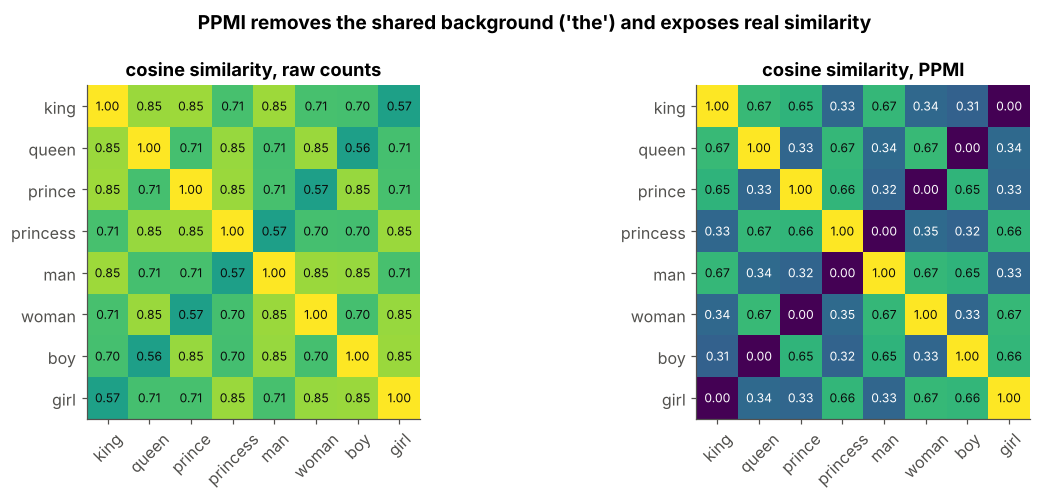

In [12]:
pi = [index[p] for p in people]
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.6))
for ax, S, title in [(axs[0], S_raw, "raw counts"), (axs[1], S_ppmi, "PPMI")]:
    sub = S[np.ix_(pi, pi)]
    im = ax.imshow(sub, cmap="viridis", vmin=0, vmax=1)
    ax.set_xticks(range(8), people, rotation=45); ax.set_yticks(range(8), people)
    for (i, j), v in np.ndenumerate(sub):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v < 0.5 else C["ink"])
    ax.set_title(f"cosine similarity, {title}"); ax.grid(False)
fig.suptitle("PPMI removes the shared background ('the') and exposes real similarity", fontweight="bold")
plt.tight_layout(); plt.show()

With raw counts every person looks similar to every other (they all share *the*). With PPMI, a person is most similar to those who share **two** of its three attributes (e.g. *king* – *queen*, *prince*, *man*) and least similar to its opposite on all three (*king* – *girl*).

---
## 7 · Playing the missing-word game with counts 🎲

We can now predict a hidden word from its context, the notes' game. For a candidate word $w$ and context words $c_1,\dots,c_r$ we ask: *how likely is this word in general, and how likely is it to be surrounded by exactly these contexts?* (a "naive Bayes" score):

$$\text{score}(w)=\log P(w)+\sum_{t=1}^{r}\log P(c_t\mid w),\qquad P(c\mid w)=\frac{X_{wc}+1}{\sum_{c'}(X_{wc'}+1)}$$

* $P(w)$ = how frequent $w$ is in the corpus;
* $P(c\mid w)$ = row $w$ of the count matrix, normalised; the $+1$ ("add-one smoothing") avoids $\log0$ for pairs never seen.

The best-scoring word is the prediction.

In [13]:
word_freq = np.array([sum(s.count(w) for s in sentences) for w in vocab])
P_w = word_freq / word_freq.sum()                               # P(w): how common each word is


def fill_gap(context, k=5):
    """Rank every vocabulary word as the filler for the given context words."""
    Xs = X + 1                                                  # add-one smoothing
    P_c_given_w = Xs / Xs.sum(axis=1, keepdims=True)           # row w holds P(c | w)
    scores = np.log(P_w) + sum(np.log(P_c_given_w[:, index[c]]) for c in context)
    for c in context:
        scores[index[c]] = -np.inf                              # do not predict a context word itself
    best = np.argsort(-scores)[:k]
    return [(vocab[j], float(scores[j])) for j in best]

**Three gaps:** the notes' sentence, a royal sentence and a fruit sentence.

In [14]:
gaps = {"i like going __ my old house": ["like", "going", "my", "old"],
        "the __ palace she works":      ["palace", "she", "works"],
        "i like the __ sweet ripe":     ["like", "sweet", "ripe"]}
gap_results = {g: fill_gap(ctx) for g, ctx in gaps.items()}
for g, res in gap_results.items():
    print(f"{g:<30} → {[w for w, _ in res]}")

i like going __ my old house   → ['to', 'house', 'i', 'money', 'shore']
the __ palace she works        → ['queen', 'the', 'king', 'princess', 'woman']
i like the __ sweet ripe       → ['tree', 'mango', 'banana', 'juicy', 'the']


📊 **Plot:** the top 5 candidates for each gap, scored relative to the best one.

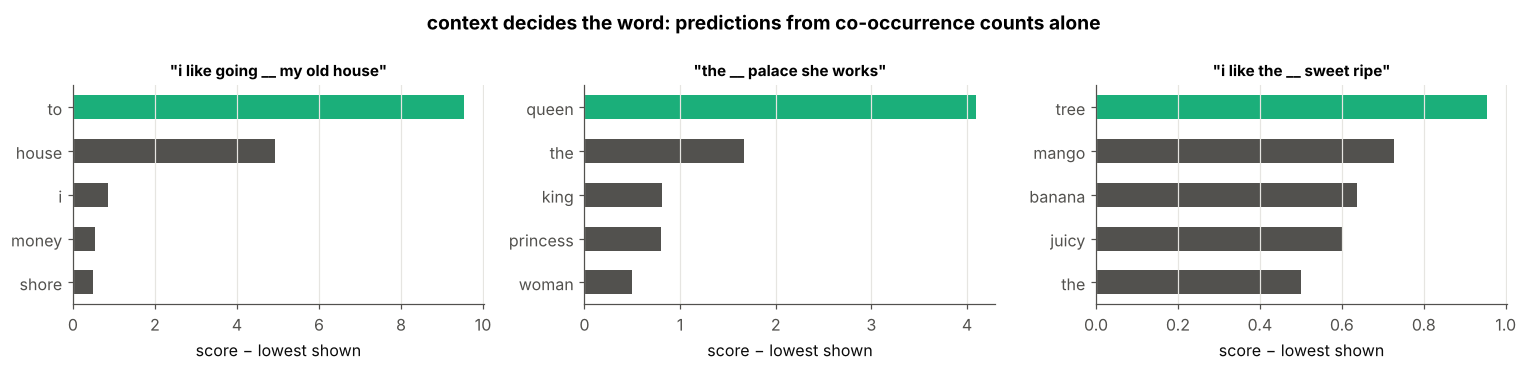

In [15]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, (g, res) in zip(axs, gap_results.items()):
    ws = [w for w, _ in res][::-1]
    sc = np.array([s for _, s in res][::-1])
    ax.barh(ws, sc - sc.min() + 0.5, color=[C["muted"]] * 4 + [C["aqua"]], height=0.55)
    ax.set_title(f'"{g}"', fontsize=10); ax.set_xlabel("score − lowest shown"); ax.grid(axis="y", visible=False)
fig.suptitle("context decides the word: predictions from co-occurrence counts alone", fontweight="bold")
plt.tight_layout(); plt.show()

Counting neighbours already "knows" that *to* fits the notes' sentence, that a female royal adult is a *queen*, and that something sweet and ripe is a fruit (its top guess *tree* is a fruit context word – it fits the gap, just not the way we meant). Word2vec will learn the same kind of knowledge – but compressed into short vectors and learned by gradient descent.

---
## 8 · From long sparse rows to short dense vectors ✂️

Each PPMI row has $n$ entries, mostly zeros. The **singular value decomposition** (SVD) writes the matrix as $PPMI=A\ \Sigma\ B^\top$, with the most important directions first. Keeping only the first $k$ columns of $A\Sigma$ gives every word a **short, dense** vector of $k$ numbers that preserves as much of the row-to-row structure as any $k$-dimensional linear projection can.

In [16]:
A_svd, sing, Bt = np.linalg.svd(PPMI)
k = 10
dense = A_svd[:, :k] * sing[:k]                       # k-dimensional word vectors
print(f"each word: {n} sparse numbers → {k} dense numbers;  first 10 singular values:", sing[:10].round(1))
S_dense = cosine_matrix(dense)
for w in ["king", "mango", "bank"]:
    print(f"{w:<6} (SVD, k={k}) → {neighbours(S_dense, w, 4)}")

each word: 75 sparse numbers → 10 dense numbers;  first 10 singular values: [22.5 17.2 15.8 15.8 15.8 13.3  8.8  8.3  8.2  7.5]
king   (SVD, k=10) → [('man', 1.0), ('queen', 1.0), ('prince', 1.0), ('woman', 1.0)]
mango  (SVD, k=10) → [('apple', 1.0), ('banana', 1.0), ('grape', 1.0), ('juicy', 0.87)]
bank   (SVD, k=10) → [('save', 0.8), ('pay', 0.8), ('cash', 0.8), ('rupees', 0.8)]


### Do the dense vectors encode the attributes as *directions*?
If *royal*, *female*, … are directions in the space, then *king − man + woman* should land near *queen* (the notes, page 6: *"king − man = queen − woman"*). Analogy test: compute the target vector, then find the nearest word (excluding the three inputs).

In [17]:
def analogy(E, a, b, c, k=3):
    """Words closest to  E[a] - E[b] + E[c]  (cosine), excluding a, b, c."""
    En = E / np.linalg.norm(E, axis=1, keepdims=True)
    q = En[index[a]] - En[index[b]] + En[index[c]]
    s = En @ q
    for w in (a, b, c):
        s[index[w]] = -np.inf
    return [vocab[j] for j in np.argsort(-s)[:k]]

for a, b, c in [("king", "man", "woman"), ("prince", "boy", "girl"), ("queen", "woman", "man")]:
    print(f"{a} − {b} + {c} ≈ {analogy(dense, a, b, c)}")

king − man + woman ≈ ['queen', 'princess', 'prince']
prince − boy + girl ≈ ['princess', 'woman', 'queen']
queen − woman + man ≈ ['king', 'prince', 'princess']


**A 2-D view of the people.** The first SVD directions separate *people* from *things*, which is not what we want to see here. So we take only the 8 people's dense vectors (normalised to length 1), centre them, and find *their* two main directions with a second, small SVD (this is PCA).

In [18]:
P_vecs = dense[[index[p] for p in people]]
P_vecs = P_vecs / np.linalg.norm(P_vecs, axis=1, keepdims=True)
P_centered = P_vecs - P_vecs.mean(axis=0)
_, _, Vt_people = np.linalg.svd(P_centered, full_matrices=False)
xy_people = P_centered @ Vt_people[:2].T                      # 2-D coordinates of the 8 people
print({p: xy_people[k].round(2).tolist() for k, p in enumerate(people)})

{'king': [0.05, 0.04], 'queen': [0.06, -0.02], 'prince': [-0.02, 0.02], 'princess': [-0.01, -0.04], 'man': [0.01, 0.04], 'woman': [0.02, -0.03], 'boy': [-0.06, 0.03], 'girl': [-0.04, -0.04]}


📊 **Plot:** the 8 people in that plane. Orange arrows join each male word to its female partner: they are (almost) **parallel and equally long** – a single "gender direction", which is exactly why *king − man + woman ≈ queen* works.

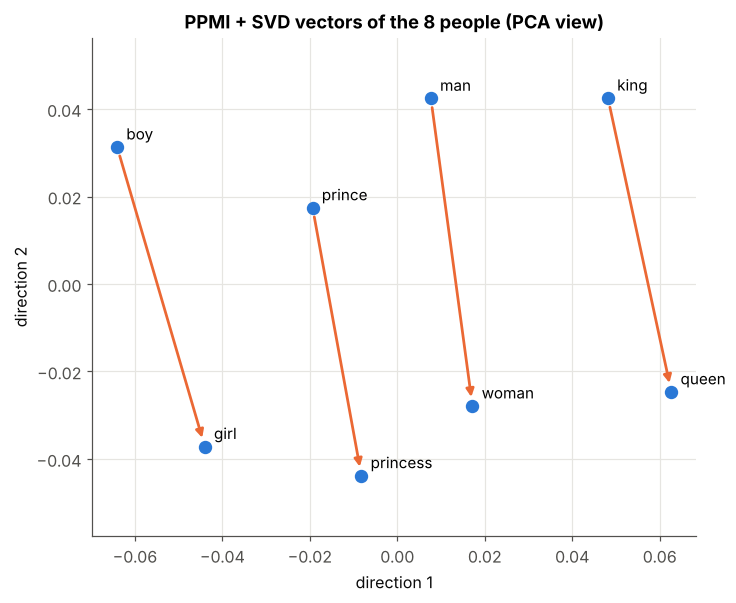

In [19]:
fig, ax = plt.subplots(figsize=(6.8, 5.6))
for k, p in enumerate(people):
    ax.scatter(*xy_people[k], color=C["blue"], s=60, zorder=3)
    ax.annotate(p, xy_people[k], textcoords="offset points", xytext=(6, 5), fontsize=10)
for a, b in [("king", "queen"), ("man", "woman"), ("prince", "princess"), ("boy", "girl")]:
    ax.annotate("", xy=xy_people[people.index(b)], xytext=xy_people[people.index(a)],
                arrowprops=dict(arrowstyle="-|>", color=C["orange"], lw=1.8, shrinkA=6, shrinkB=6))
ax.set_title("PPMI + SVD vectors of the 8 people (PCA view)"); ax.set_xlabel("direction 1"); ax.set_ylabel("direction 2")
ax.set_aspect("equal", adjustable="datalim")
plt.tight_layout(); plt.show()

---
## 9 · Two different ideas: distributed vs distributional 🧠

The notes (page 9) separate two properties that are easy to confuse:

* **Distributional semantics** – *talks about the value in each dimension*: the numbers are derived from the **contexts** the word appears in.
* **Distributed representation** – *talks about what each dimension represents*: meaning is **spread over many dimensions**, no single dimension means "royal" or "document 3"; the vector is short and dense.

| | **distributed: yes** | **distributed: no** |
|---|---|---|
| **distributional: yes** | **word2vec** (and PPMI + SVD) | **TF-IDF word vectors** (one dimension per document) |
| **distributional: no** | **knowledge-graph embeddings** (learned from facts like *elephant –is a→ mammal*) | **one-hot encoding** |

Word2vec, coming next, sits in the top-left cell: dense vectors **learned** from context, rather than counted and factorised.

---
## 10 · Summary 📌

| Step | Formula / idea |
|---|---|
| co-occurrence | $X_{ij}$ = times $w_j$ is within $m$ words of $w_i$ |
| similarity | $\cos(X_i, X_j)$ |
| PPMI | $\max\left(0,\ \log\dfrac{P(i,j)}{P(i)P(j)}\right)$ – removes "background" words |
| dense vectors | keep $k$ columns of the SVD of PPMI |
| missing word | $\arg\max_w\sum_t\log P(w\mid c_t)$ |

**Limitations that word2vec addresses:** the $n\times n$ matrix is enormous for real vocabularies ($10^5\times10^5$), the SVD of it is expensive, and adding new text means recomputing everything. Word2vec learns dense vectors directly, one example at a time.

### ✍️ Try it yourself
1. Change the window to $m=1$ and $m=6$. How do the neighbours of `king` change?
2. Run `analogy` on the **raw counts** `X` instead of `dense`. Does it still work?
3. Use `k = 2` and `k = 20` in the SVD. Which value gives the best analogies?
4. Find a gap where the count model fails. Why does it fail?

**Next →** `03 - PageRank Analogy`: a *recursive* definition of importance, solved by iterating to a steady state.